In [1]:
!pip install -q ultralytics opencv-python-headless

In [2]:
import cv2, collections
import matplotlib.pyplot as plt
from google.colab import files
from ultralytics import YOLO

# Pre-trained on COCO. Use yolov8s.pt or yolov8m.pt for better accuracy
model = YOLO("yolov8n.pt")

TARGETS = ["person", "bicycle", "car", "motorcycle", "bus", "truck"]

def detect_and_count(frame, conf=0.35):
    result = model(frame, conf=conf, verbose=False)[0]
    counts = collections.Counter()
    for box in result.boxes:
        name = model.names[int(box.cls)]
        if name in TARGETS:
            counts[name] += 1
    return result, counts

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


Saving Busy Urban Street with Varied Traffic.png to Busy Urban Street with Varied Traffic.png


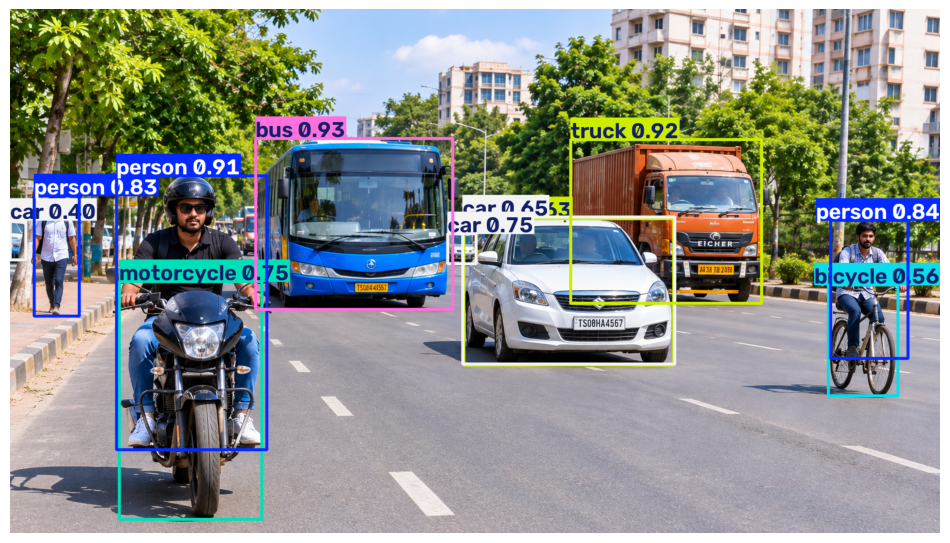

Detection summary
-------------------------
person      : 3
bicycle     : 1
car         : 3
motorcycle  : 1
bus         : 1
truck       : 2
-------------------------
Total objects: 11


In [4]:
uploaded = files.upload()
img_path = list(uploaded.keys())[0]

img = cv2.imread(img_path)
result, counts = detect_and_count(img)

annotated = result.plot()
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

print("Detection summary")
print("-" * 25)
for cls in TARGETS:
    print(f"{cls:<12}: {counts.get(cls, 0)}")
print("-" * 25)
print("Total objects:", sum(counts.values()))